#Part A

In [1]:
import tensorflow as tf
from keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import cv2
import numpy as np
import pandas as pd

### Loading datasets

In [2]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

4431872/4422102 [==============================] - 0s 0us/step


In [3]:
type(x_train)

numpy.ndarray

In [4]:
x_train[0].shape,y_train[0].shape,x_test[0].shape,y_test.shape

((28, 28), (), (28, 28), (10000,))

### Plot grayscale images

In [5]:
def plot_images(img):
  
  plt.figure(figsize=(10,4))
  plt.imshow(img, cmap = 'gray')

### Flip the image

In [6]:
def mirror(img):
  image = cv2.flip(img,1)
  return image

In [7]:
img = mirror(x_train[0])
img.shape

(28, 28)

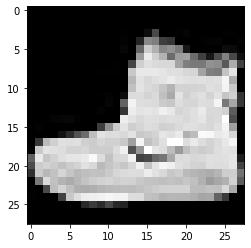

In [8]:
plot_images(x_train[0])

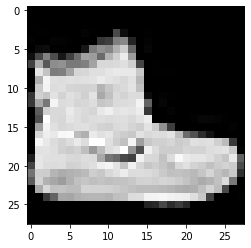

In [9]:
plot_images(img)

(None, None)

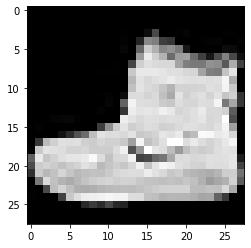

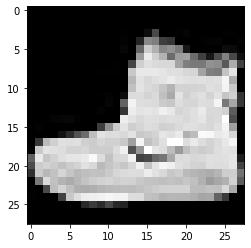

In [10]:
plot_images(x_train[0]/255),plot_images(x_train[0])

In [11]:
x_train= x_train/255.0
x_test=x_test/255.0


In [12]:
y_train.shape

(60000,)

In [13]:
y_train = y_train.reshape(-1,1)
y_train.shape

(60000, 1)

In [14]:
y_test = y_test.reshape(-1,1)
y_test.shape

(10000, 1)

#### flipping image

In [15]:
x_train_mirror = []
for i in x_train:
  x_train_mirror.append(mirror(i))
x_train_mirror = np.array(x_train_mirror)
x_train_mirror.shape

(60000, 28, 28)

In [16]:
x_test_mirror = []
for i in x_test:
  x_test_mirror.append(mirror(i))
x_test_mirror = np.array(x_test_mirror)
x_test_mirror.shape

(10000, 28, 28)

In [17]:
y_train[0]

array([9], dtype=uint8)

(None, None)

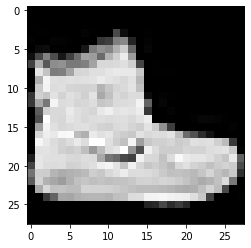

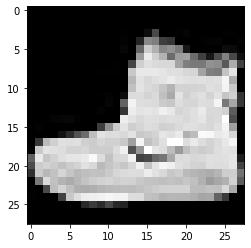

In [18]:
plot_images(x_train_mirror[0]),plot_images(x_train[0])

In [19]:
d = {
0: 'T-shirt/top',
1 : 'Trouser',
2 : 'Pullover',
3 : 'Dress',
4 : 'Coat',
5 : 'Sandal',
6 : 'Shirt',
7 : 'Sneaker',
8 : 'Bag',
9 : 'Ankle boot'
}

In [20]:
x_train_mod = np.vstack((x_train,x_train_mirror))
x_train_mod.shape

(120000, 28, 28)

In [21]:
y_train_mod = np.vstack((y_train,y_train))
y_train_mod.shape

(120000, 1)

In [22]:
y_train_mod[1],y_train_mod[60001]

(array([0], dtype=uint8), array([0], dtype=uint8))

In [23]:
x_test_mod = np.vstack((x_test,x_test_mirror))
x_test_mod.shape

(20000, 28, 28)

In [24]:
y_test_mod = np.vstack((y_test,y_test))
y_test_mod.shape

(20000, 1)

In [25]:
y_test_mod[1],y_test_mod[10001]

(array([2], dtype=uint8), array([2], dtype=uint8))

In [26]:
def plot_color_images(img):
  
  plt.figure(figsize=(10,4))
  plt.imshow(img)

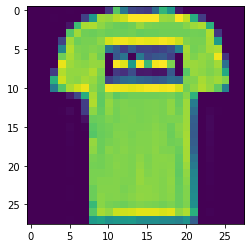

In [27]:
plot_color_images(x_train_mod[1])

### Power law transform

In [28]:
def power_law(img):
  gamma = 0.2
  gamma_corrected = np.array(255*(img) ** gamma, dtype = 'uint8')
  #plot_images(gamma_corrected)
  #plot_color_images(gamma_corrected)
  #print(gamma_corrected)
  return gamma_corrected


In [29]:
img = power_law(x_train_mod[0])

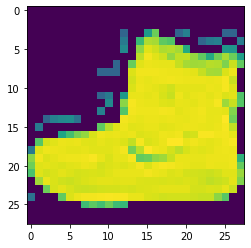

In [30]:
plot_color_images(img)

In [31]:
x_train_gamma = np.array(255*(x_train) ** 0.2, dtype = 'uint8')
x_train_gamma.shape

(60000, 28, 28)

In [32]:
x_test_gamma = np.array(255*(x_test) ** 0.2, dtype = 'uint8')
x_test_gamma.shape

(10000, 28, 28)

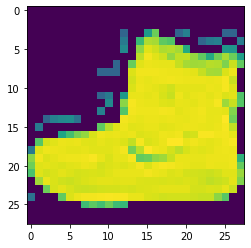

In [33]:
plot_color_images(x_train_gamma[0])


In [34]:
x_train_mod = np.vstack((x_train_mod,x_train_gamma))
x_train_mod.shape

(180000, 28, 28)

In [35]:
x_test_mod = np.vstack((x_test_mod,x_test_gamma))
x_test_mod.shape

(30000, 28, 28)

In [36]:
y_train_mod = np.vstack((y_train_mod,y_train))
y_train_mod.shape

(180000, 1)

In [37]:
y_test_mod = np.vstack((y_test_mod,y_test))
y_test_mod.shape

(30000, 1)

In [38]:
x_train_mod.shape,y_train_mod.shape,x_test_mod.shape,y_test_mod.shape

((180000, 28, 28), (180000, 1), (30000, 28, 28), (30000, 1))

In [39]:
x_train = x_train_mod.copy()
x_train.shape

(180000, 28, 28)

In [40]:
y_train = y_train_mod.copy()
y_train.shape

(180000, 1)

In [41]:
x_val = x_test_mod[15000:]
x_test = x_test_mod[:15000]
x_val.shape,x_test.shape

((15000, 28, 28), (15000, 28, 28))

In [42]:
y_val = y_test_mod[15000:]
y_test = y_test_mod[:15000]
y_val.shape,y_test.shape

((15000, 1), (15000, 1))

#Part B

## Loading Libraries

In [43]:
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten

In [44]:
x_train = x_train.reshape(x_train.shape[0], 28, 28, 1)
x_test = x_test.reshape(x_test.shape[0], 28, 28, 1)

In [45]:
y_train = y_train.reshape(180000)
y_test = y_test.reshape(-1)
y_val = y_val.reshape(-1)
y_test.shape

(15000,)

## convolution neural network

In [80]:
num_filters = 64
filter_size1 = 3
pool_size1 = 2

In [104]:
model1 = Sequential()
model1.add(Conv2D(filters=num_filters, kernel_size=filter_size1, input_shape=(28,28,1),padding='same',activation = 'relu')) 
model1.add(MaxPooling2D(pool_size = pool_size1))
model1.add(Conv2D(filters=num_filters, kernel_size=filter_size1, padding='same',activation = 'relu')) 
model1.add(MaxPooling2D(pool_size = pool_size1))
model1.add(Flatten())
model2.add(Dense(256, activation='relu'))
model1.add(Dense(10,activation = 'softmax'))

In [105]:
model1.summary()

Model: "sequential_12"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_24 (Conv2D)          (None, 28, 28, 64)        640       
                                                                 
 max_pooling2d_24 (MaxPoolin  (None, 14, 14, 64)       0         
 g2D)                                                            
                                                                 
 conv2d_25 (Conv2D)          (None, 14, 14, 64)        36928     
                                                                 
 max_pooling2d_25 (MaxPoolin  (None, 7, 7, 64)         0         
 g2D)                                                            
                                                                 
 flatten_12 (Flatten)        (None, 3136)              0         
                                                                 
 dense_15 (Dense)            (None, 10)              

In [106]:
model1.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

model1.fit(x_train, to_categorical(y_train), epochs = 5, verbose = 1, validation_data = (x_val, to_categorical(y_val
                                                                                                              )))

Epoch 1/5
5625/5625 [==============================] - 42s 7ms/step - loss: 0.5565 - accuracy: 0.8115 - val_loss: 0.4130 - val_accuracy: 0.8487
Epoch 2/5
5625/5625 [==============================] - 41s 7ms/step - loss: 0.3604 - accuracy: 0.8690 - val_loss: 0.3798 - val_accuracy: 0.8631
Epoch 3/5
5625/5625 [==============================] - 41s 7ms/step - loss: 0.3197 - accuracy: 0.8822 - val_loss: 0.3713 - val_accuracy: 0.8634
Epoch 4/5
5625/5625 [==============================] - 42s 7ms/step - loss: 0.2991 - accuracy: 0.8895 - val_loss: 0.3767 - val_accuracy: 0.8625
Epoch 5/5
5625/5625 [==============================] - 42s 7ms/step - loss: 0.2876 - accuracy: 0.8936 - val_loss: 0.3546 - val_accuracy: 0.8731


In [107]:
loss1,score1 = model1.evaluate(x_test, to_categorical(y_test), verbose=0)
print("Loss: ",loss1)
print('Accuracy', score1)

Loss:  0.29241740703582764
Accuracy 0.8939333558082581


In [108]:
predictions = model1.predict(x_test[:10])
print(np.argmax(predictions, axis = 1))

[9 2 1 1 6 1 4 6 5 7]


In [109]:
y_test[:10]

array([9, 2, 1, 1, 6, 1, 4, 6, 5, 7], dtype=uint8)

#Part C

In [87]:
from keras.layers import BatchNormalization,Dropout

## Dropout regularization

In [100]:

model2 = Sequential()
model2.add(Conv2D(filters=num_filters, kernel_size=filter_size1, input_shape=(28,28,1),padding='same',activation = 'relu')) 
model2.add(MaxPooling2D(pool_size = pool_size1))
model2.add(Dropout(0.2))
model2.add(Conv2D(filters=num_filters, kernel_size=filter_size1, padding='same',activation = 'relu')) 
model2.add(MaxPooling2D(pool_size = pool_size1))
model2.add(Dropout(0.2))
model2.add(Flatten())
model2.add(Dense(256, activation='relu'))
model2.add(Dropout(0.2))
model2.add(Dense(10,activation = 'softmax'))

In [101]:
model2.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

model2.fit(x_train, to_categorical(y_train), epochs = 5, verbose = 1, validation_data = (x_val, to_categorical(y_val
                                                                                                              )))

Epoch 1/5
5625/5625 [==============================] - 51s 9ms/step - loss: 0.6427 - accuracy: 0.7818 - val_loss: 0.4416 - val_accuracy: 0.8301
Epoch 2/5
5625/5625 [==============================] - 51s 9ms/step - loss: 0.4052 - accuracy: 0.8500 - val_loss: 0.4237 - val_accuracy: 0.8457
Epoch 3/5
5625/5625 [==============================] - 50s 9ms/step - loss: 0.3635 - accuracy: 0.8652 - val_loss: 0.3480 - val_accuracy: 0.8667
Epoch 4/5
5625/5625 [==============================] - 51s 9ms/step - loss: 0.3469 - accuracy: 0.8714 - val_loss: 0.3365 - val_accuracy: 0.8773
Epoch 5/5
5625/5625 [==============================] - 50s 9ms/step - loss: 0.3347 - accuracy: 0.8769 - val_loss: 0.3328 - val_accuracy: 0.8779


In [102]:
model2.summary()

Model: "sequential_11"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_22 (Conv2D)          (None, 28, 28, 64)        640       
                                                                 
 max_pooling2d_22 (MaxPoolin  (None, 14, 14, 64)       0         
 g2D)                                                            
                                                                 
 dropout_8 (Dropout)         (None, 14, 14, 64)        0         
                                                                 
 conv2d_23 (Conv2D)          (None, 14, 14, 64)        36928     
                                                                 
 max_pooling2d_23 (MaxPoolin  (None, 7, 7, 64)         0         
 g2D)                                                            
                                                                 
 dropout_9 (Dropout)         (None, 7, 7, 64)        

In [103]:
loss2,score2 = model2.evaluate(x_test, to_categorical(y_test), verbose=0)
print("Loss: ",loss2)
print('Accuracy', score2)

Loss:  0.2769969701766968
Accuracy 0.897266685962677


## Batch Normalization

In [110]:
model3 = Sequential()

model3.add(Conv2D(filters=num_filters, kernel_size=filter_size1, input_shape=(28,28,1),padding='same',activation = 'relu')) 
model3.add(BatchNormalization())
model3.add(MaxPooling2D(pool_size = pool_size1))
model3.add(Conv2D(filters=num_filters, kernel_size=filter_size1, padding='same',activation = 'relu')) 
model3.add(BatchNormalization())
model3.add(MaxPooling2D(pool_size = pool_size1))
model3.add(Flatten())
model2.add(Dense(256, activation='relu'))
model3.add(BatchNormalization())
model3.add(Dense(10,activation = 'softmax'))

In [111]:
model3.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

model3.fit(x_train, to_categorical(y_train), epochs = 5, verbose = 1, validation_data = (x_val, to_categorical(y_val
                                                                                                              )))

Epoch 1/5
5625/5625 [==============================] - 53s 9ms/step - loss: 0.6042 - accuracy: 0.8016 - val_loss: 0.6514 - val_accuracy: 0.8207
Epoch 2/5
5625/5625 [==============================] - 51s 9ms/step - loss: 0.4330 - accuracy: 0.8519 - val_loss: 0.4689 - val_accuracy: 0.8565
Epoch 3/5
5625/5625 [==============================] - 52s 9ms/step - loss: 0.3611 - accuracy: 0.8692 - val_loss: 0.3961 - val_accuracy: 0.8582
Epoch 4/5
5625/5625 [==============================] - 51s 9ms/step - loss: 0.3322 - accuracy: 0.8783 - val_loss: 0.3592 - val_accuracy: 0.8686
Epoch 5/5
5625/5625 [==============================] - 52s 9ms/step - loss: 0.3154 - accuracy: 0.8836 - val_loss: 0.3682 - val_accuracy: 0.8687


In [112]:


model3.summary()

Model: "sequential_13"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_26 (Conv2D)          (None, 28, 28, 64)        640       
                                                                 
 batch_normalization_6 (Batc  (None, 28, 28, 64)       256       
 hNormalization)                                                 
                                                                 
 max_pooling2d_26 (MaxPoolin  (None, 14, 14, 64)       0         
 g2D)                                                            
                                                                 
 conv2d_27 (Conv2D)          (None, 14, 14, 64)        36928     
                                                                 
 batch_normalization_7 (Batc  (None, 14, 14, 64)       256       
 hNormalization)                                                 
                                                     

In [95]:

loss3,score3 = model3.evaluate(x_test, to_categorical(y_test), verbose=0)
print("Loss: ",loss3)
print('Accuracy', score3)

Loss:  0.3133034110069275
Accuracy 0.8871999979019165
